# Método adaptativo (AMM) para opciones barrera

**Objetivo.** Valuar una call europea *down-and-out* con árboles trinomiales y mostrar:

1. Por qué el trinomial estándar converge de forma errática cuando hay una barrera.
2. Cómo mejora al poner una capa de nodos sobre la barrera (RTM, Ritchken 1995), y por qué igual se vuelve inmanejable cuando el precio inicial está muy cerca de la barrera.
3. Cómo el ***A**daptive **M**esh **M**odel* (a.k.a. **AMM**) resuelve el problema agregando malla fina solo cerca de la barrera.

El código está en el paquete `amm` (`src/amm/`). Acá se importa y se usa.

In [1]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from amm import (amm_gao, 
                 arbol_barrera,
                 call_down_and_out,
                 probabilidades,
                 rtm_ritchken,
                 trinomial_estandar_gao,
                 paso_temporal)

plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 150, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8, "axes.edgecolor": "#b5b4ad", "lines.linewidth": 2,
    "font.size": 10, "legend.frameon": False,
})

# Todos los gráficos se guardan en notebooks/graphs/
GRAPHS = Path("graphs")
GRAPHS.mkdir(exist_ok=True)

def guardar(fig, nombre):
    fig.savefig(GRAPHS / f"{nombre}.png", bbox_inches="tight")

# Parámetros del paper (secc. 4.1)
P = dict(K=100, T=1.0, r=0.10, sigma=0.25, H=90)

## 1. Opciones barrera y el árbol trinomial

Una **call down-and-out** paga $\max(S_T-K,0)$ al vencimiento, salvo que el precio haya tocado la
barrera $H<S_0$ antes: en ese caso se extingue (*knock-out*) y no paga nada.

### Valor analítico (ec. 8, Merton 1973)

Con barrera continua y $H \le K$:

$$
C_{DO} = C_{BS}(S) - \left(\frac{H}{S}\right)^{2\lambda - 2} C_{BS}\!\left(\frac{H^2}{S}\right),
\qquad \lambda = \frac{r + \sigma^2/2}{\sigma^2}.
$$

Lo usamos como referencia para medir el error de cada método.

### Trinomial en $\ln S$ (ecs. 7 y 9)

Para que las capas de nodos estén siempre al mismo precio, el árbol se arma sobre $X=\ln S$ sin
restar la media. En cada paso $X$ sube $h$, queda igual o baja $h$, con probabilidades que
ajustan la media $\alpha k$ ($\alpha = r - \sigma^2/2$) y la varianza $\sigma^2 k$:

$$
p_u = \tfrac12\!\left(\frac{\sigma^2 k}{h^2} + \frac{\alpha^2 k^2}{h^2} + \frac{\alpha k}{h}\right),\quad
p_d = \tfrac12\!\left(\frac{\sigma^2 k}{h^2} + \frac{\alpha^2 k^2}{h^2} - \frac{\alpha k}{h}\right),\quad
p_m = 1-p_u-p_d .
$$

El valor se obtiene hacia atrás: $C(X,t) = e^{-rk}\,[p_u C(X+h) + p_m C(X) + p_d C(X-h)]$.
El paso de precio se liga al de tiempo con $h = \sigma\sqrt{\lambda k}$ y se toma $\lambda=3$ (ec. 11).

In [2]:
exacto_100 = call_down_and_out(100, **P)
print(f"Valor analítico (S=100): {exacto_100:.4f}   (paper: 11.323)")

k = 1 / 100
h = P["sigma"] * np.sqrt(3 * k)
p_u, p_m, p_d = probabilidades(h, k, P["r"], P["sigma"])
print(f"Ejemplo N=100: h={h:.4f}  p_u={p_u:.4f}  p_m={p_m:.4f}  p_d={p_d:.4f}")

Valor analítico (S=100): 11.3234   (paper: 11.323)
Ejemplo N=100: h=0.0433  p_u=0.1747  p_m=0.6664  p_d=0.1589


## 2. Convergencia del trinomial estándar (Fig. 3 del paper)

Con el árbol centrado en $S_0$ la barrera casi nunca cae sobre un nodo. Al aumentar $N$, el paso
$h$ se achica de a poco, y cada tanto el número de bajadas necesarias para tocar la barrera
salta en uno: la probabilidad de *knock-out* cae de golpe y el precio salta. El resultado es
una convergencia en "serrucho" que **sobrevalúa** la opción (la barrera efectiva queda más lejos
que la real).

199 árboles en 2.3 s


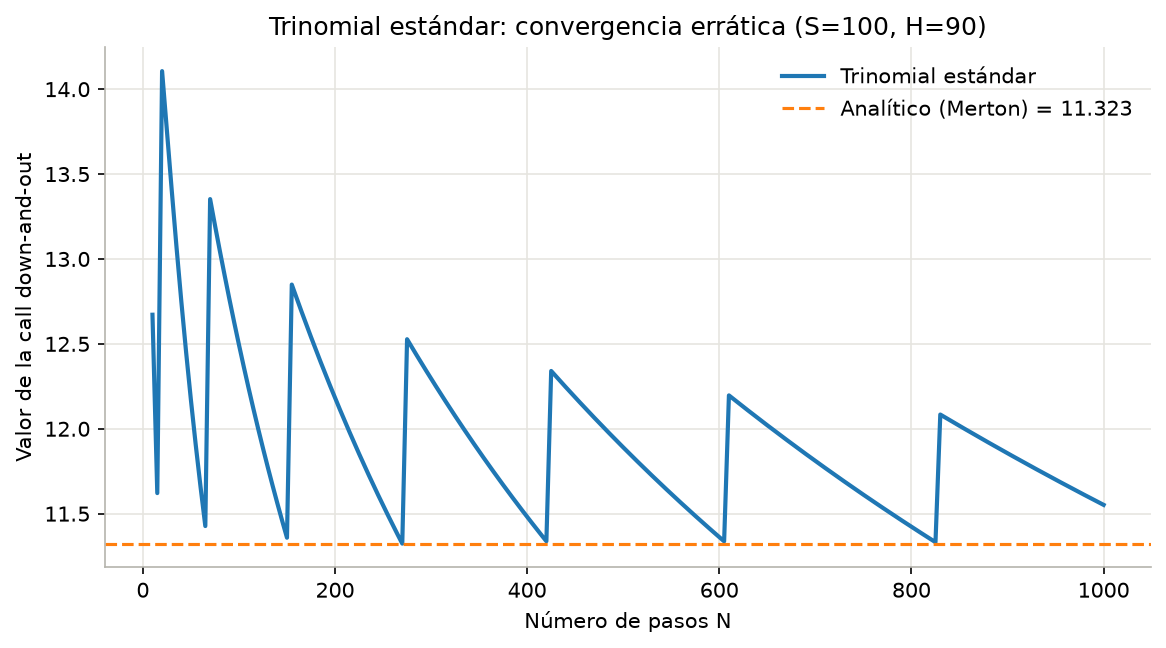

In [3]:
Ns = np.arange(10, 1001, 5)
t0 = time.perf_counter()
valores_std = np.array([trinomial_estandar_gao(100, N=N, **P) for N in Ns])
print(f"{len(Ns)} árboles en {time.perf_counter() - t0:.1f} s")

fig, ax = plt.subplots()
ax.plot(Ns, valores_std, color="tab:blue" , label="Trinomial estándar")
ax.axhline(exacto_100, color="tab:orange", lw=1.5, ls="--", label=f"Analítico (Merton) = {exacto_100:.3f}")
ax.set(xlabel="Número de pasos N", ylabel="Valor de la call down-and-out",
       title="Trinomial estándar: convergencia errática (S=100, H=90)")
ax.legend()
guardar(fig, "01_trinomial_estandar_convergencia")
plt.show()

## 3. Barrera sobre una capa de nodos: el RTM

La solución de Ritchken (1995), ***R**estricted **T**rinomial **M**odel*, es elegir el paso de precio para
que la barrera quede exactamente $n$ pasos por debajo de $S_0$: $h = \ln(S_0/H)/n$. Luego el paso
de tiempo se ajusta para tener un número entero de pasos (ec. 17):

$$ k = \frac{T}{\operatorname{int}\!\left(\lambda\sigma^2 T / h^2\right)} .$$

La convergencia pasa a ser suave y monótona:

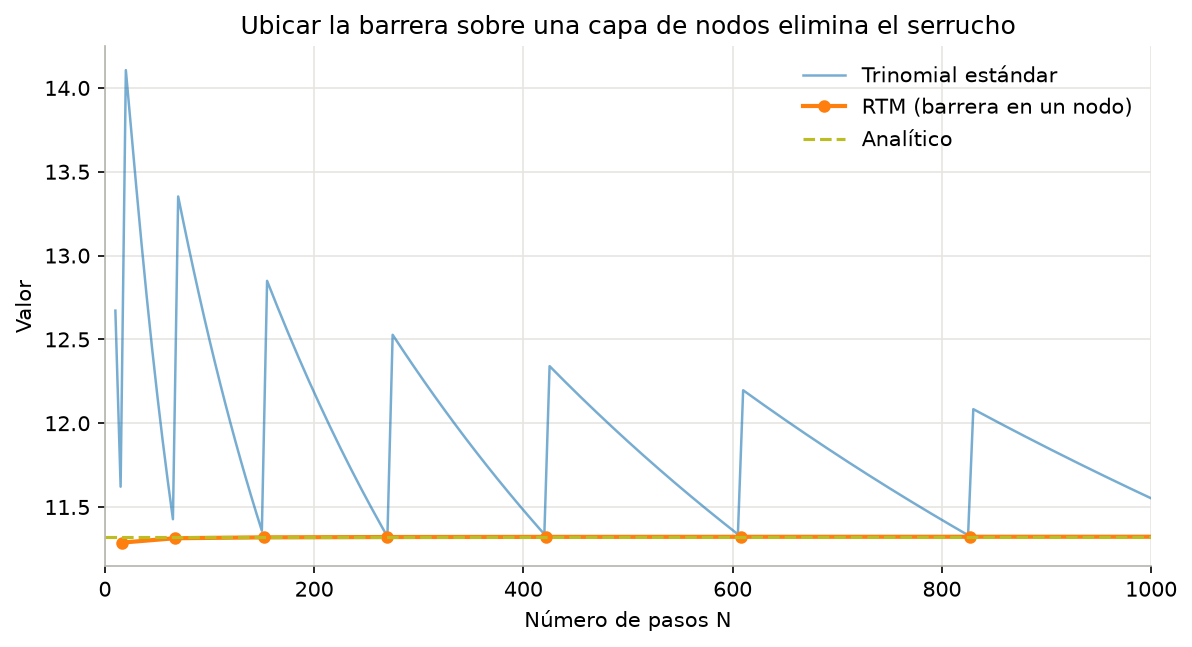

,pasos hasta H,N,valor
0,1,16,11.287638
1,2,67,11.313815
2,3,152,11.319077
3,4,270,11.320962
4,5,422,11.321828
5,6,608,11.322297
6,7,827,11.322582
7,8,1080,11.322766


In [4]:
filas = []
for n in range(1, 31):
    v, N = rtm_ritchken(100, pasos_hasta_barrera=n, **P)
    filas.append((n, N, v))
rtm100 = pd.DataFrame(filas, columns=["pasos hasta H", "N", "valor"])

fig, ax = plt.subplots()
ax.plot(Ns, valores_std, color="tab:blue", lw=1.2, alpha=0.6, label="Trinomial estándar")
ax.plot(rtm100["N"], rtm100["valor"], color="tab:orange", marker="o", ms=5, label="RTM (barrera en un nodo)")
ax.axhline(exacto_100, color="tab:olive", lw=1.5, ls="--", label="Analítico")
ax.set(xlabel="Número de pasos N", ylabel="Valor", xlim=(0, 1000),
       title="Ubicar la barrera sobre una capa de nodos elimina el serrucho")
ax.legend()
guardar(fig, "02_rtm_vs_trinomial")
plt.show()
rtm100.head(8)

Los puntos del RTM caen justo en los mínimos del serrucho: son los $N$ para los que, en el trinomial
estándar, la barrera queda exactamente sobre una capa de nodos.

### El problema: $S_0$ muy cerca de la barrera

Si $S_0 = 90.5$ y $H=90$, el mayor paso que deja la barrera a un paso de distancia es
$h=\ln(90.5/90)=0.00554$. Con $\lambda=3$ eso exige $k=0.000164$ años: **6108 pasos** y unos
37 millones de nodos. Cada vez que la distancia a la barrera se divide por 2, $N$ se multiplica
por 4 y los nodos por 16. El trinomial estándar, por su parte, sigue muy lejos del valor correcto
con 1000 pasos:

In [5]:
for S in [92, 91, 90.5, 90.25, 90.125]:
    h = np.log(S / P["H"])
    _, N = paso_temporal(h, P["T"], P["sigma"])
    print(f"S0={S:<7}  h={h:.5f}  N necesario (RTM) = {N:>6,}   nodos ≈ {(N + 1) ** 2:>15,}")

v = trinomial_estandar_gao(90.5, N=1000, **P)
ex = call_down_and_out(90.5, **P)
print(f"\nTrinomial estándar, S0=90.5, N=1000: {v:.3f}  vs analítico {ex:.3f}  (error {v / ex - 1:+.0%})")

S0=92       h=0.02198  N necesario (RTM) =    388   nodos ≈         151,321
S0=91       h=0.01105  N necesario (RTM) =  1,535   nodos ≈       2,359,296
S0=90.5     h=0.00554  N necesario (RTM) =  6,108   nodos ≈      37,319,881
S0=90.25    h=0.00277  N necesario (RTM) = 24,367   nodos ≈     593,799,424
S0=90.125   h=0.00139  N necesario (RTM) = 97,335   nodos ≈   9,474,296,896

Trinomial estándar, S0=90.5, N=1000: 1.521  vs analítico 0.642  (error +137%)


> El paper reporta 1.102 para el trinomial estándar con $N=1000$; acá da distinto porque el valor
> exacto depende de cómo cae la barrera entre nodos para ese $N$ en particular, pero la conclusión
> es la misma: el error es enorme.

## 4. El Adaptive Mesh Model para barreras (secc. 4.2–4.4)

La idea del AMM es usar una **malla gruesa** (pasos $h$, $k$) en todo el árbol y agregar una
**malla fina** (pasos $h/2$, $k/4$) solo en la franja pegada a la barrera. Como $p \approx \sigma^2 k/h^2$,
reducir $h$ a la mitad y $k$ a la cuarta parte mantiene las probabilidades casi iguales.

La información fluye **de la malla gruesa hacia la fina**:

1. **Malla gruesa (nodos A).** Se elige $h = 2(\ln S_0 - \ln H)$ (ec. 16), así $S_0$ queda a media
   distancia entre la barrera y el primer nodo grueso $\ln H + h$. Con $k$ de la ec. (17) se valúa
   la retícula gruesa con la barrera sobre una capa de nodos.
2. **Nodos ancla (B sobre $\ln H$ y $\ln H + h$).** En $\ln H$ el valor es 0 (knock-out). En
   $\ln H + h$ hacen falta valores cada $k/4$: los que coinciden con un paso grueso son nodos A; los
   intermedios se calculan desde los tres nodos A del paso grueso siguiente con un **paso efectivo**
   de $3k/4$, $2k/4$ o $k/4$ (ecs. 12–13):
   $$C(B) = e^{-r\,\Delta t}\left[p_u(h,\Delta t)\,A_{2,j+1} + p_m(h,\Delta t)\,A_{1,j+1} + p_d(h,\Delta t)\,A_{0,j+1}\right].$$
3. **Línea del medio ($\ln H + h/2$).** Se recorre hacia atrás desde el vencimiento con probabilidades
   $(h/2, k/4)$ (ecs. 14–15), usando como vecinos la barrera y la línea ancla. Su valor en $t=0$ es
   el precio en $S_0$.

**Más niveles (secc. 4.4).** Si $S_0$ está todavía más cerca, se repite el procedimiento: con $M$
niveles, $h = 2^M(\ln S_0-\ln H)$ (ec. 18) y cada nivel agrega una línea a mitad de distancia de la
barrera, con paso de tiempo 4 veces menor. Cada nivel agrega solo $10\cdot 4^{m-1} N$ nodos.

El esquema de la Fig. 6 del paper (un nivel de malla fina, tres pasos gruesos):

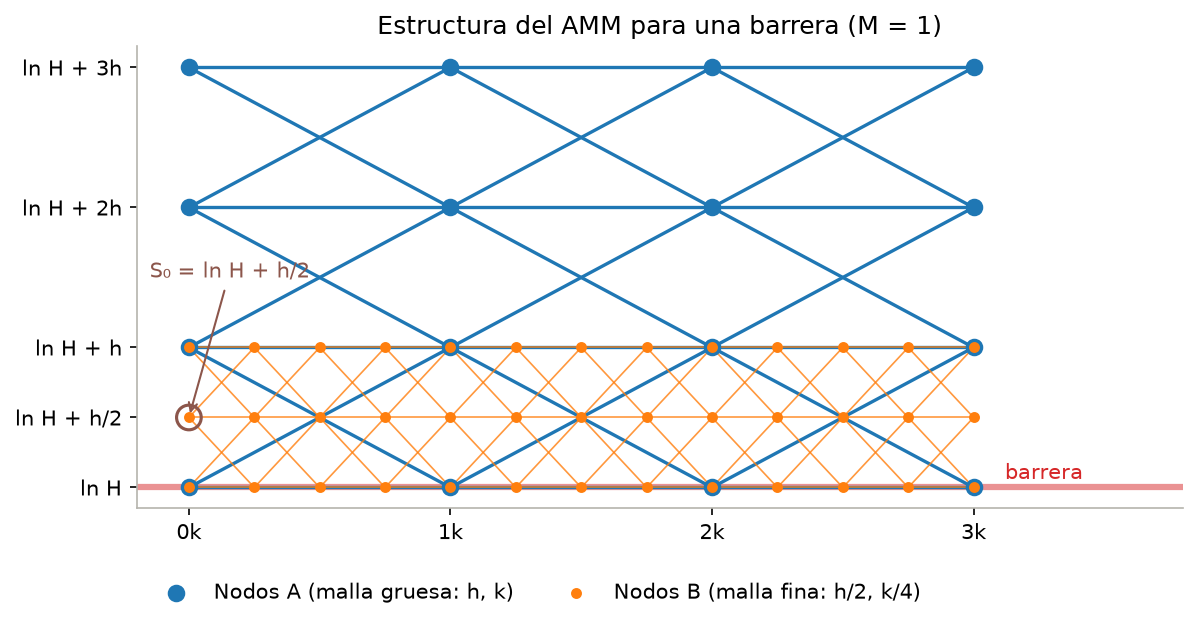

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
nk = 3                                                          # pasos gruesos dibujados
for j in range(nk):                                             # malla gruesa
    for i in range(0, 4):
        for di in (-1, 0, 1):
            if 0 <= i + di <= 3:
                ax.plot([j, j + 1], [i, i + di], color="tab:blue", lw=1.6, zorder=1)
tf = np.arange(0, nk + 1e-9, 0.25)
for t in tf[:-1]:                                               # malla fina (h/2, k/4)
    for y in (0, 0.5, 1):
        for dy in (-0.5, 0, 0.5):
            if 0 <= y + dy <= 1:
                ax.plot([t, t + 0.25], [y, y + dy], color="tab:orange", lw=0.8, alpha=0.8, zorder=2)
J, I = np.meshgrid(np.arange(nk + 1), np.arange(4))
ax.scatter(J, I, s=55, color="tab:blue", zorder=3, label="Nodos A (malla gruesa: h, k)")
ax.scatter(np.repeat(tf, 3), np.tile([0, 0.5, 1], tf.size), s=18, color="tab:orange", zorder=4,
           label="Nodos B (malla fina: h/2, k/4)")
ax.scatter([0], [0.5], s=140, facecolor="none", edgecolor="tab:brown", lw=1.5, zorder=5)
ax.annotate("S₀ = ln H + h/2", (0, 0.5), (-0.15, 1.5), color="tab:brown", arrowprops=dict(arrowstyle="->", lw=1, color="tab:brown"))
ax.axhline(0, color="tab:red", lw=3, alpha=0.5, zorder=0)
ax.text(nk + 0.12, 0.1, "barrera", va="center", color="tab:red")
ax.set(xticks=range(nk + 1), xticklabels=[f"{j}k" for j in range(nk + 1)],
       yticks=[0, 0.5, 1, 2, 3], yticklabels=["ln H", "ln H + h/2", "ln H + h", "ln H + 2h", "ln H + 3h"],
       xlim=(-0.2, nk + 0.8), title="Estructura del AMM para una barrera (M = 1)")
ax.grid(False)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.12), ncol=2)
guardar(fig, "03_estructura_amm")
plt.show()

## 5. Resultados: replicación de la Tabla 3

Valuamos la call ($K=100$, $H=90$, $T=1$, $r=10\%$, $\sigma=0.25$) para precios iniciales cada vez
más cerca de la barrera. El RTM usa un paso igual a $\ln(S_0/H)$; el AMM mantiene un paso grueso de
unos 2 puntos ($\approx\ln(92/90)$) y agrega niveles de malla fina a medida que $S_0 \to H$.

`CORRER_LENTO = True` incluye el RTM para $S_0=90.125$ (≈97 000 pasos; tarda minutos).

In [7]:
CORRER_LENTO = False

def cronometrar(f, *a, **kw):
    t0 = time.perf_counter()
    salida = f(*a, **kw)
    return salida, time.perf_counter() - t0

filas = []
for S in [92, 91, 90.5, 90.25, 90.125]:
    exacto = call_down_and_out(S, **P)
    (v_amm, M, _), t_amm = cronometrar(amm_gao, S, **P)
    h = np.log(S / P["H"])
    _, N_rtm = paso_temporal(h, P["T"], P["sigma"])
    if N_rtm < 50_000 or CORRER_LENTO:
        (v_rtm, _), t_rtm = cronometrar(rtm_ritchken, S, **P)
    else:
        v_rtm, t_rtm = np.nan, np.nan
    filas.append(dict(S0=S, analitico=exacto, RTM=v_rtm, N_RTM=N_rtm, t_RTM_s=t_rtm,
                     AMM=v_amm, nivel_M=M, t_AMM_s=t_amm))

tabla3 = pd.DataFrame(filas).set_index("S0")

# Eficiencia: cuántas veces más rápido es el AMM, y cuánto crece el tiempo de cada método
# respecto de la fila anterior (distancia a la barrera dividida por 2)
tabla3["RTM/AMM"] = tabla3["t_RTM_s"] / tabla3["t_AMM_s"]
tabla3["x_t_RTM"] = tabla3["t_RTM_s"] / tabla3["t_RTM_s"].shift()
tabla3["x_t_AMM"] = tabla3["t_AMM_s"] / tabla3["t_AMM_s"].shift()

tabla3.style.format_index("{:g}").format({"analitico": "{:.4f}", "RTM": "{:.4f}", "AMM": "{:.4f}", "N_RTM": "{:,}",
                     "t_RTM_s": "{:.3f}", "t_AMM_s": "{:.4f}", "RTM/AMM": "{:,.0f}×",
                     "x_t_RTM": "×{:.1f}", "x_t_AMM": "×{:.1f}"}, na_rep="—")

,analitico,RTM,N_RTM,t_RTM_s,AMM,nivel_M,t_AMM_s,RTM/AMM,x_t_RTM,x_t_AMM
S0,,,,,,,,,,
92,2.5063,2.5062,388,0.008,2.5062,0,0.0095,1×,—,—
91,1.2738,1.2738,"1,535",0.037,1.2738,1,0.0095,4×,×4.8,×1.0
90.5,0.6424,0.6424,"6,108",0.235,0.6424,2,0.0142,17×,×6.3,×1.5
90.25,0.3226,0.3226,"24,367",2.312,0.3226,3,0.0285,81×,×9.8,×2.0
90.125,0.1616,—,"97,335",—,0.1617,4,0.0928,—,—,×3.3


> Valores del paper (Tabla 3):
> El AMM coincide con el analítico al tercer decimal; también coinciden los pasos del RTM. Los tiempos son
mucho menores que los del paper (una PC Pentium de 90 MHz en 1999), pero el patrón se mantiene:
cada vez que la distancia a la barrera se divide por 2, los nodos del RTM se multiplican por un factor de 16,
mientras que el tiempo del AMM casi no cambia.

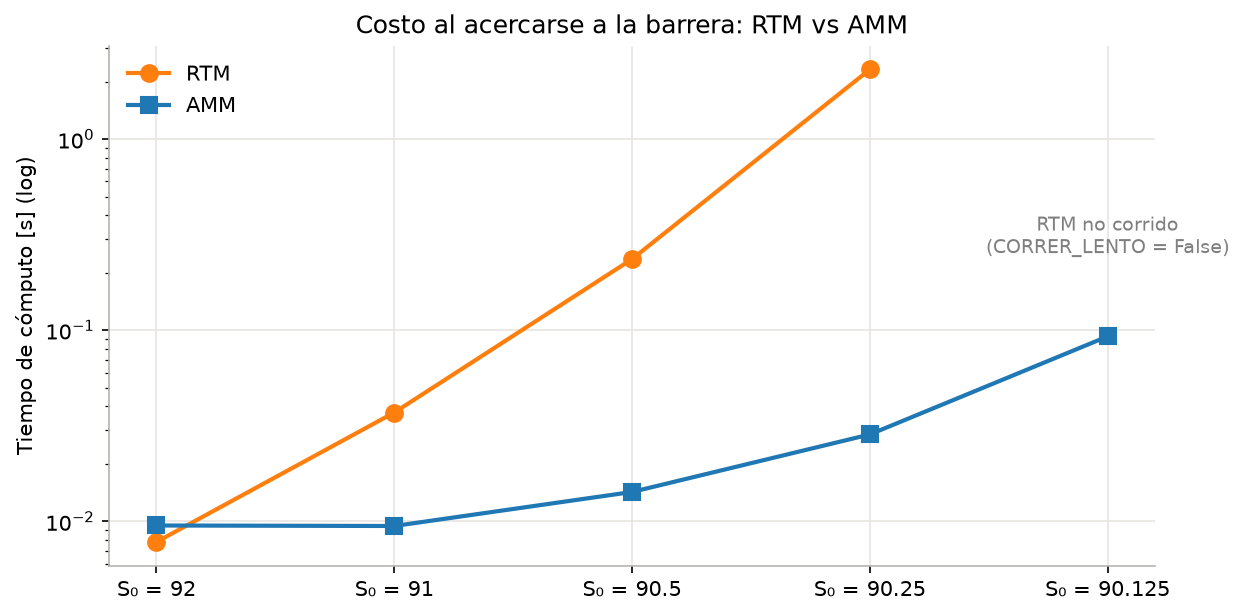

In [8]:
fig, ax = plt.subplots()
x = np.arange(len(tabla3))
ax.semilogy(x, tabla3["t_RTM_s"], color="tab:orange", marker="o", ms=8, label="RTM")
ax.semilogy(x, tabla3["t_AMM_s"], color="tab:blue", marker="s", ms=8, label="AMM")
for xi, t in zip(x, tabla3["t_RTM_s"]):
    if np.isnan(t):
        ax.annotate("RTM no corrido\n(CORRER_LENTO = False)", (xi, tabla3["t_AMM_s"].iloc[xi]), ha="center",
                    textcoords="offset points", xytext=(0, 40), color="tab:grey", fontsize=9)
ax.set(xticks=x, xticklabels=[f"S₀ = {s:g}" for s in tabla3.index], ylabel="Tiempo de cómputo [s] (log)",
       title="Costo al acercarse a la barrera: RTM vs AMM")
ax.legend(loc="upper left")
guardar(fig, "04_tiempos_rtm_vs_amm")
plt.show()

## 6. Precisión vs costo

Para $S_0 = 90.5$ comparamos el error absoluto contra el tiempo de cómputo de los tres métodos:
el trinomial estándar con distintos $N$, el RTM con 1 y 2 pasos hasta la barrera, y el AMM con
distintos pasos gruesos (lo que cambia $M$ y $N$).

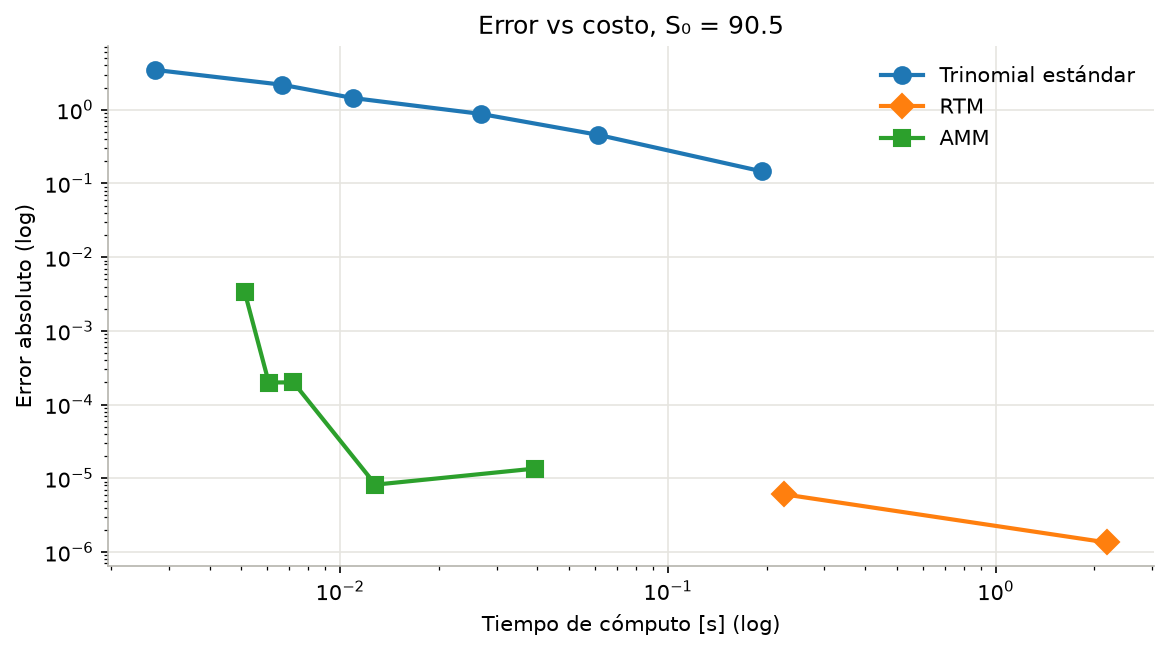

,método,config,tiempo_s,error_abs
0,Trinomial estándar,N=100,0.0027,3.47e+00
1,Trinomial estándar,N=250,0.0067,2.19e+00
2,Trinomial estándar,N=500,0.0109,1.44e+00
3,Trinomial estándar,N=1000,0.0269,8.78e-01
4,Trinomial estándar,N=2000,0.0614,4.56e-01
5,Trinomial estándar,N=4000,0.1935,1.46e-01
6,RTM,N=6108,0.2260,6.07e-06
7,RTM,N=24435,2.1782,1.35e-06
8,AMM,"M=5, N=5",0.0051,3.37e-03
9,AMM,"M=4, N=23",0.0061,1.99e-04


In [9]:
S = 90.5
exacto = call_down_and_out(S, **P)
resultados = []
for N in [100, 250, 500, 1000, 2000, 4000]:
    v, t = cronometrar(trinomial_estandar_gao, S, N=N, **P)
    resultados.append(("Trinomial estándar", f"N={N}", t, abs(v - exacto)))
for n in [1, 2]:
    (v, N), t = cronometrar(rtm_ritchken, S, pasos_hasta_barrera=n, **P)
    resultados.append(("RTM", f"N={N}", t, abs(v - exacto)))
for hg in [0.16, 0.08, 0.04, 0.02, 0.01]:
    (v, M, N), t = cronometrar(amm_gao, S, h_grueso=hg, **P)
    resultados.append(("AMM", f"M={M}, N={N}", t, abs(v - exacto)))
costo = pd.DataFrame(resultados, columns=["método", "config", "tiempo_s", "error_abs"])

fig, ax = plt.subplots()
for nombre, color, marcador in [("Trinomial estándar", "tab:blue", "o"), ("RTM", "tab:orange", "D"), ("AMM", "tab:green", "s")]:
    d = costo[costo["método"] == nombre]
    ax.loglog(d["tiempo_s"], d["error_abs"], color=color, marker=marcador, ms=8, label=nombre)
ax.set(xlabel="Tiempo de cómputo [s] (log)", ylabel="Error absoluto (log)",
       title=f"Error vs costo, S₀ = {S}")
ax.legend()
guardar(fig, "05_error_vs_costo")
plt.show()
costo.style.format({"tiempo_s": "{:.4f}", "error_abs": "{:.2e}"})

## 7. Conclusiones

- Con una barrera, el trinomial estándar converge en serrucho y sobrevalúa la down-and-out,
  porque la barrera efectiva del árbol queda más lejos que la real.
- Ubicar la barrera sobre una capa de nodos (RTM) arregla la convergencia, pero el paso de precio
  queda atado a la distancia $\ln(S_0/H)$: cerca de la barrera, $N$ crece como $1/d^2$ y los nodos
  como $1/d^4$.
- El AMM desacopla las dos cosas: la malla gruesa resuelve el problema "global" y la malla fina,
  que solo agrega $O(N)$ nodos por nivel, resuelve la no linealidad cerca de la barrera. Con eso
  reproduce los valores de la Tabla 3 en milisegundos, incluso para $S_0 = 90.125$ donde el RTM
  necesita casi 100 000 pasos.
- La misma idea sirve para otros puntos de alta no linealidad (el strike al vencimiento, sección 3
  del paper).